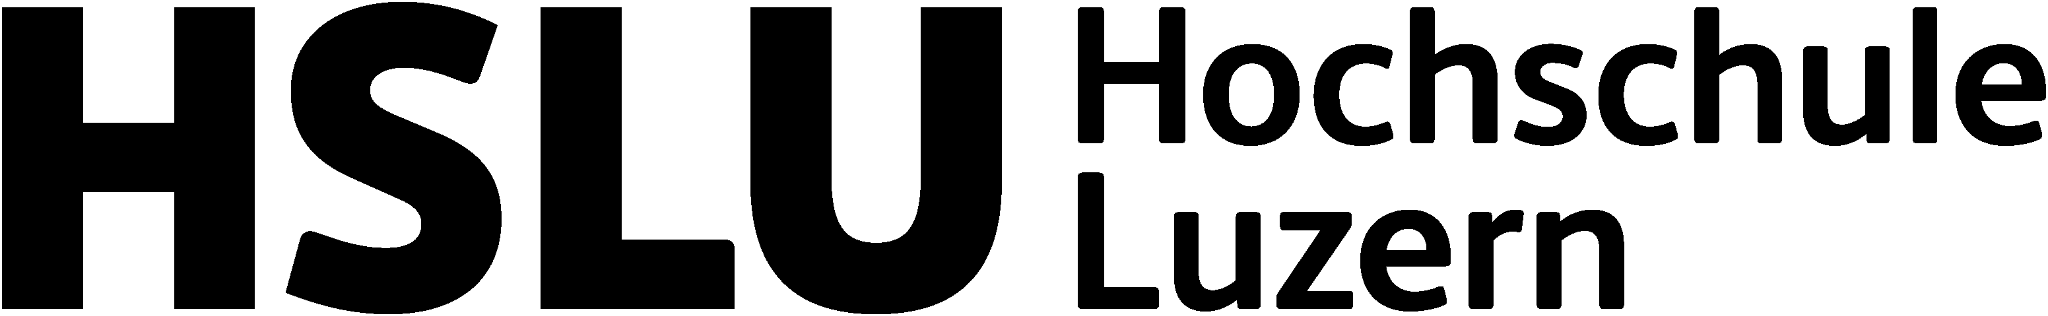

# From Text Retrieval to Graph-Enhanced RAG

**Computational Language Technologies · MSc Applied Data Science and AI**  
**Morning 2 companion tutorial · Courses 4, 5, and 6**

<div style="border-left:6px solid #D95D4F; padding:10px 14px; background:#F8F4EE; margin:18px 0;">
<b>Guiding question</b><br>
When does structured knowledge improve retrieval—and how can we demonstrate that it did?
</div>

This is one **self-contained tutorial notebook**. The core path needs **no API key** and uses a small, explicitly fictional AI-media corpus. We freeze the corpus and evaluation questions, build a transparent BM25 baseline, add graph-based retrieval, assemble evidence packets, and evaluate retrieval, context, and answers separately.

## Learning objectives

By the end, you should be able to:

1. build and inspect a sparse text-retrieval baseline;
2. define required evidence before tuning a RAG system;
3. connect query entities to a provenance-bearing knowledge graph;
4. expand graph neighbourhoods while controlling hops, relation types, and time;
5. combine graph-selected candidates with their source passages;
6. diagnose retrieval, context, and answer failures separately;
7. compare a text baseline with a graph variant by question category;
8. formulate and test one targeted enhancement rather than add complexity indiscriminately.

<div style="border-left:6px solid #3D7C83; padding:10px 14px; background:#EEF5F6;">
<b>Boundary with the deep-learning part of the course</b><br>
Dense retrieval uses learned representations, but representation learning itself is covered elsewhere. Here we focus on retrieval contracts, explicit graph constraints, provenance, failure analysis, and evaluation. The interfaces below can later accept a dense or hybrid retriever without changing the evaluation logic.
</div>

## Two ways to use the notebook

| Path | Approx. time | What to run |
|---|---:|---|
| **Live core path** | 35–45 min | Cells marked **CORE**; discuss one graph success and one graph failure |
| **Complete tutorial** | 90–120 min | Run everything, complete the checkpoints, and try the stress test and exercises |

**Notation**

- 🔴 **CORE** — essential experimental path
- ◇ **CHECKPOINT** — predict or interpret before continuing
- ↗ **EXTENSION** — useful after class

All organisations, models, hardware, standards, publications, URLs, and claims are **synthetic teaching data**. They deliberately reproduce realistic retrieval problems but are not news reports.

<details>
<summary><b>Suggested live route</b></summary>

| Minute | Focus | Live action |
|---:|---|---|
| 0–5 | Experimental contract | Freeze passages, questions, and required evidence |
| 5–12 | Text baseline | Build BM25; inspect a top-k ranking |
| 12–18 | Baseline evaluation | Measure evidence recall and identify one failure |
| 18–27 | Graph enhancement | Link entities; expand a two-hop, time-aware neighbourhood |
| 27–34 | Controlled comparison | Compare text, always-on graph, and routed graph retrieval |
| 34–41 | RAG evidence packet | Assemble passages; run the fixed evidence-first answerer |
| 41–45 | Three-layer evaluation | Separate retriever, context, and answer diagnostics |

The remaining sections are designed for independent work after class.
</details>

## Experimental journey

```text
frozen passages + frozen questions
            ↓
       BM25 baseline
            ↓
  evaluate → inspect errors
            ↓
entity linking + graph expansion
            ↓
retrieve source passages, not bare triples
            ↓
compare retrieval → context → answer
            ↓
discuss benefit, failure, latency, and maintenance cost
```

We compare three systems:

| System | Purpose |
|---|---|
| `TEXT` | frozen BM25 baseline |
| `GRAPH_ALWAYS` | graph expansion whenever an entity is linkable; intentionally exposes noise |
| `GRAPH_ROUTED_TIME` | graph only for relational/temporal needs, with validity filtering |

The third system is a **testable hypothesis**, not an assumed improvement.

# 0 · Environment and reproducibility

🔴 **CORE**

In [1]:
# Install only packages that are missing. A standard Google Colab runtime
# normally already contains these dependencies.
import importlib.util
import subprocess
import sys

REQUIRED = {
    "pandas": "pandas>=2.0",
    "numpy": "numpy>=1.24",
    "sklearn": "scikit-learn>=1.3",
    "matplotlib": "matplotlib>=3.7",
}

missing = [spec for module, spec in REQUIRED.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already available.")

All required packages are already available.


In [2]:
from __future__ import annotations

import hashlib
import json
import math
import re
import statistics
import time
import unicodedata
from collections import Counter, defaultdict, deque
from copy import deepcopy
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 40)
plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(7)

PALETTE = {
    "ink": "#17212B",
    "coral": "#D95D4F",
    "teal": "#3D7C83",
    "gold": "#C89B3C",
    "cobalt": "#3659D9",
    "slate": "#6C7A89",
    "paper": "#F8F4EE",
}

print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · NumPy {np.__version__}")

Python 3.12.14 · pandas 2.2.3 · NumPy 2.3.5


### Reproducibility contract

The experiment below holds the following constant unless a cell explicitly says otherwise:

- corpus and passage boundaries;
- test questions and required evidence;
- tokenizer and BM25 parameters;
- `top_k = 3`;
- answerer and evaluation rules.

The graph variant may change **only the retrieval route**. This isolation is what lets us attribute observed differences to the enhancement rather than to a new prompt, generator, corpus, or question set.

# 1 · Freeze the corpus and the evaluation questions

🔴 **CORE**

A RAG experiment begins with an evidence contract, not with a vector database.

Each passage retains:

- a stable passage and document ID;
- source, publication time, and topic track;
- source-faithful text;
- an optional validity interval for the claim expressed in that passage.

Publication time and claim-validity time are different. A 2026 article may describe a contract that expired in 2025; retrieval and generation should not collapse those two notions of time.

In [3]:
# Explicitly fictional AI-media passages.
passages = [
    {
        "passage_id": "P001", "doc_id": "D001",
        "title": "Helios-3 preview scheduled", "source": "AI Ledger",
        "published_at": "2026-09-14", "track": "Foundation Models",
        "text": "Orion Labs said Helios-3 will enter public preview in October 2026.",
        "claim_valid_from": None, "claim_valid_to": None,
    },
    {
        "passage_id": "P002", "doc_id": "D002",
        "title": "Helios-3 training infrastructure", "source": "Compute Wire",
        "published_at": "2026-05-12", "track": "Hardware and Infrastructure",
        "text": "Orion Labs reported that Helios-3 was trained on Atlas X accelerators.",
        "claim_valid_from": "2026-01-01", "claim_valid_to": "2026-12-31",
    },
    {
        "passage_id": "P003", "doc_id": "D003",
        "title": "Atlas X supply for the 2026 run", "source": "Compute Wire",
        "published_at": "2026-05-20", "track": "Hardware and Infrastructure",
        "text": "Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.",
        "claim_valid_from": "2026-01-01", "claim_valid_to": "2026-12-31",
    },
    {
        "passage_id": "P004", "doc_id": "D004",
        "title": "Earlier Atlas X supply agreement", "source": "Infrastructure Review",
        "published_at": "2025-01-08", "track": "Hardware and Infrastructure",
        "text": "Northstar Systems began supplying Atlas X accelerators to Orion Labs in January 2025; the agreement expired on 31 December 2025.",
        "claim_valid_from": "2025-01-01", "claim_valid_to": "2025-12-31",
    },
    {
        "passage_id": "P005", "doc_id": "D005",
        "title": "Atlas X efficiency result", "source": "Benchmark Brief",
        "published_at": "2026-06-02", "track": "Hardware and Infrastructure",
        "text": "Atlas X led the GreenCompute efficiency benchmark, according to Orion Labs.",
        "claim_valid_from": "2026-06-02", "claim_valid_to": None,
    },
    {
        "passage_id": "P006", "doc_id": "D006",
        "title": "The Helios model family", "source": "Model Observer",
        "published_at": "2026-08-23", "track": "Foundation Models",
        "text": "Orion Labs developed Helios-3 from the earlier Helios-2 family.",
        "claim_valid_from": None, "claim_valid_to": None,
    },
    {
        "passage_id": "P007", "doc_id": "D007",
        "title": "Aster adopts ToolBridge", "source": "Agent Web Journal",
        "published_at": "2026-07-05", "track": "Agentic Web",
        "text": "Aster Runtime implements the ToolBridge standard for tool discovery.",
        "claim_valid_from": "2026-07-05", "claim_valid_to": None,
    },
    {
        "passage_id": "P008", "doc_id": "D008",
        "title": "Nimbus exposes services", "source": "Agent Web Journal",
        "published_at": "2026-07-07", "track": "Agentic Web",
        "text": "Nimbus Tools exposes its weather and market services through ToolBridge.",
        "claim_valid_from": "2026-07-07", "claim_valid_to": None,
    },
    {
        "passage_id": "P009", "doc_id": "D009",
        "title": "Agent interoperability test", "source": "Protocol Watch",
        "published_at": "2026-07-08", "track": "Agentic Web",
        "text": "Aster Runtime connected to Nimbus Tools during a public interoperability test.",
        "claim_valid_from": "2026-07-08", "claim_valid_to": None,
    },
    {
        "passage_id": "P010", "doc_id": "D010",
        "title": "Quanta connector strategy", "source": "Protocol Watch",
        "published_at": "2026-07-09", "track": "Agentic Web",
        "text": "Quanta Agents uses a proprietary connector and does not implement ToolBridge.",
        "claim_valid_from": "2026-07-09", "claim_valid_to": None,
    },
    {
        "passage_id": "P011", "doc_id": "D011",
        "title": "Helios-3 enters public preview", "source": "AI Ledger",
        "published_at": "2026-10-10", "track": "Foundation Models",
        "text": "Helios-3 entered public preview on 8 October 2026.",
        "claim_valid_from": "2026-10-08", "claim_valid_to": None,
    },
    {
        "passage_id": "P012", "doc_id": "D012",
        "title": "Solstice expands production", "source": "Industry Signal",
        "published_at": "2026-05-21", "track": "Hardware and Infrastructure",
        "text": "Solstice Components, also known as Solstice, expanded accelerator production in Basel.",
        "claim_valid_from": None, "claim_valid_to": None,
    },
    {
        "passage_id": "P013", "doc_id": "D013",
        "title": "Analyst note on Atlas X", "source": "Market Lens",
        "published_at": "2026-05-25", "track": "Hardware and Infrastructure",
        "text": "An analyst note discussed Northstar Systems and Atlas X benchmark results without describing a supply relationship.",
        "claim_valid_from": None, "claim_valid_to": None,
    },
    {
        "passage_id": "P014", "doc_id": "D014",
        "title": "Undisclosed training details", "source": "Model Observer",
        "published_at": "2026-05-30", "track": "Foundation Models",
        "text": "Orion Labs did not disclose exact training energy consumption for Helios-3.",
        "claim_valid_from": None, "claim_valid_to": None,
    },
]

passages_df = pd.DataFrame(passages)
passage_by_id = {p["passage_id"]: p for p in passages}
display(passages_df[["passage_id", "published_at", "track", "title", "text"]])

,passage_id,published_at,track,title,text
0,P001,2026-09-14,Foundation Models,Helios-3 preview scheduled,Orion Labs said Helios-3 will enter public preview in October 2026.
1,P002,2026-05-12,Hardware and Infrastructure,Helios-3 training infrastructure,Orion Labs reported that Helios-3 was trained on Atlas X accelerators.
2,P003,2026-05-20,Hardware and Infrastructure,Atlas X supply for the 2026 run,Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.
3,P004,2025-01-08,Hardware and Infrastructure,Earlier Atlas X supply agreement,Northstar Systems began supplying Atlas X accelerators to Orion Labs in January 2025; the agreement expired on 31 De...
4,P005,2026-06-02,Hardware and Infrastructure,Atlas X efficiency result,"Atlas X led the GreenCompute efficiency benchmark, according to Orion Labs."
5,P006,2026-08-23,Foundation Models,The Helios model family,Orion Labs developed Helios-3 from the earlier Helios-2 family.
6,P007,2026-07-05,Agentic Web,Aster adopts ToolBridge,Aster Runtime implements the ToolBridge standard for tool discovery.
7,P008,2026-07-07,Agentic Web,Nimbus exposes services,Nimbus Tools exposes its weather and market services through ToolBridge.
8,P009,2026-07-08,Agentic Web,Agent interoperability test,Aster Runtime connected to Nimbus Tools during a public interoperability test.
9,P010,2026-07-09,Agentic Web,Quanta connector strategy,Quanta Agents uses a proprietary connector and does not implement ToolBridge.


In [4]:
# Freeze a content fingerprint so accidental corpus edits are visible.
corpus_payload = json.dumps(passages, sort_keys=True, ensure_ascii=False).encode("utf-8")
CORPUS_SHA256 = hashlib.sha256(corpus_payload).hexdigest()
print("Passages:", len(passages))
print("Corpus SHA-256:", CORPUS_SHA256)
print("Track distribution:")
print(passages_df["track"].value_counts().to_string())

Passages: 14
Corpus SHA-256: 20b756478088a27395d79419414d9edadb2e96efd2990c7a6291c723d4ea1dbc
Track distribution:
track
Hardware and Infrastructure    6
Foundation Models              4
Agentic Web                    4


### Evaluation records include required evidence

A reference answer alone is insufficient for diagnosing retrieval. Each question therefore records the passage or passages required to support the answer.

- A direct lookup may need one passage.
- A relational question may require two linked passages.
- An unanswerable question has no required passage and should trigger abstention.
- A temporal or comparative question carries an explicit time scope.

The `answer_task` field configures the fixed tutorial answerer. It does **not** expose the reference answer or required-evidence IDs to the answerer.

In [5]:
questions = [
    {
        "question_id": "Q01", "category": "factual",
        "question": "When did Helios-3 enter public preview?",
        "required_evidence": ["P011"], "reference_answer": "8 October 2026",
        "answer_keys": ["8 october 2026"], "answer_task": "preview_actual",
        "time_scope": None, "answerable": True,
    },
    {
        "question_id": "Q02", "category": "factual",
        "question": "What month was the Helios-3 public preview scheduled for?",
        "required_evidence": ["P001"], "reference_answer": "October 2026",
        "answer_keys": ["october 2026"], "answer_task": "preview_scheduled",
        "time_scope": None, "answerable": True,
    },
    {
        "question_id": "Q03", "category": "relational",
        "question": "Who supplied the accelerator used to train Helios-3 in 2026?",
        "required_evidence": ["P002", "P003"], "reference_answer": "Solstice Components",
        "answer_keys": ["solstice components"], "answer_task": "supplier_2026_chain",
        "time_scope": ["2026-01-01", "2026-12-31"], "answerable": True,
    },
    {
        "question_id": "Q04", "category": "temporal",
        "question": "Who supplied Atlas X under the 2025 agreement?",
        "required_evidence": ["P004"], "reference_answer": "Northstar Systems",
        "answer_keys": ["northstar systems"], "answer_task": "supplier_2025",
        "time_scope": ["2025-01-01", "2025-12-31"], "answerable": True,
    },
    {
        "question_id": "Q05", "category": "entity-centric",
        "question": "Which company supplied Atlas-X for the 2026 run?",
        "required_evidence": ["P003"], "reference_answer": "Solstice Components",
        "answer_keys": ["solstice components"], "answer_task": "supplier_2026_direct",
        "time_scope": ["2026-01-01", "2026-12-31"], "answerable": True,
    },
    {
        "question_id": "Q06", "category": "relational",
        "question": "Which standard connects Aster Runtime to Nimbus Tools?",
        "required_evidence": ["P007", "P008"], "reference_answer": "ToolBridge",
        "answer_keys": ["toolbridge"], "answer_task": "agent_standard",
        "time_scope": None, "answerable": True,
    },
    {
        "question_id": "Q07", "category": "factual",
        "question": "Who developed Helios-3?",
        "required_evidence": ["P006"], "reference_answer": "Orion Labs",
        "answer_keys": ["orion labs"], "answer_task": "developer",
        "time_scope": None, "answerable": True,
    },
    {
        "question_id": "Q08", "category": "unanswerable",
        "question": "What is the exact parameter count of Helios-3?",
        "required_evidence": [], "reference_answer": "Insufficient evidence",
        "answer_keys": ["insufficient evidence"], "answer_task": "parameter_count",
        "time_scope": None, "answerable": False,
    },
    {
        "question_id": "Q09", "category": "negation",
        "question": "Does Quanta Agents implement ToolBridge?",
        "required_evidence": ["P010"],
        "reference_answer": "No. Quanta Agents does not implement ToolBridge.",
        "answer_keys": ["does not implement toolbridge"], "answer_task": "quanta_negation",
        "time_scope": None, "answerable": True,
    },
    {
        "question_id": "Q10", "category": "comparative-temporal",
        "question": "How did the Atlas X supplier relationship change from 2025 to 2026?",
        "required_evidence": ["P004", "P003"],
        "reference_answer": "Northstar Systems supplied Atlas X in 2025; Solstice Components supplied it in 2026.",
        "answer_keys": ["northstar systems", "solstice components"],
        "answer_task": "supplier_change", "time_scope": ["2025-01-01", "2026-12-31"],
        "answerable": True,
    },
    {
        "question_id": "Q11", "category": "factual",
        "question": "Which efficiency benchmark did Atlas X lead?",
        "required_evidence": ["P005"], "reference_answer": "GreenCompute",
        "answer_keys": ["greencompute"], "answer_task": "benchmark",
        "time_scope": None, "answerable": True,
    },
]

questions_df = pd.DataFrame(questions)
question_by_id = {q["question_id"]: q for q in questions}

passage_ids = set(passage_by_id)
assert len(passage_ids) == len(passages), "Passage IDs must be unique"
assert len(question_by_id) == len(questions), "Question IDs must be unique"
assert all(set(q["required_evidence"]) <= passage_ids for q in questions)

display(questions_df[["question_id", "category", "question", "required_evidence", "time_scope"]])

,question_id,category,question,required_evidence,time_scope
0,Q01,factual,When did Helios-3 enter public preview?,[P011],None
1,Q02,factual,What month was the Helios-3 public preview scheduled for?,[P001],None
2,Q03,relational,Who supplied the accelerator used to train Helios-3 in 2026?,"[P002, P003]","[2026-01-01, 2026-12-31]"
3,Q04,temporal,Who supplied Atlas X under the 2025 agreement?,[P004],"[2025-01-01, 2025-12-31]"
4,Q05,entity-centric,Which company supplied Atlas-X for the 2026 run?,[P003],"[2026-01-01, 2026-12-31]"
5,Q06,relational,Which standard connects Aster Runtime to Nimbus Tools?,"[P007, P008]",None
6,Q07,factual,Who developed Helios-3?,[P006],None
7,Q08,unanswerable,What is the exact parameter count of Helios-3?,[],None
8,Q09,negation,Does Quanta Agents implement ToolBridge?,[P010],None
9,Q10,comparative-temporal,How did the Atlas X supplier relationship change from 2025 to 2026?,"[P004, P003]","[2025-01-01, 2026-12-31]"


◇ **CHECKPOINT — predict before retrieval**

1. Which questions should BM25 solve with one passage?
2. Which questions require more than lexical similarity?
3. For which questions could a graph make retrieval worse?
4. Which questions require explicit temporal filtering?

Write down two predictions. We will compare them with the measured results rather than relying on intuition after the fact.

# 2 · Build a transparent BM25 text baseline

🔴 **CORE · Course 5**

BM25 is a strong, interpretable sparse baseline. It rewards query terms that are rare in the corpus, discounts repeated occurrences, and normalises for passage length.

For query term $t$ and passage $d$:

$$
\operatorname{BM25}(q,d)=\sum_{t\in q}
\operatorname{IDF}(t)
\frac{f(t,d)(k_1+1)}{f(t,d)+k_1\left(1-b+b\frac{|d|}{\operatorname{avgdl}}\right)}
$$

This implementation is intentionally small enough to inspect. Production systems should use a tested search engine and record analyzer settings, index version, filters, and ranking parameters.

In [6]:
def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKC", text).casefold().replace("-", " ")
    return re.sub(r"\s+", " ", text).strip()


def tokenize(text: str) -> list[str]:
    return re.findall(r"[a-z0-9]+", normalize_text(text))


class BM25Index:
    def __init__(self, records, k1: float = 1.5, b: float = 0.75):
        self.records = list(records)
        self.k1 = k1
        self.b = b
        self.doc_tokens = [tokenize(r["text"]) for r in self.records]
        self.doc_lengths = np.array([len(tokens) for tokens in self.doc_tokens], dtype=float)
        self.avgdl = float(self.doc_lengths.mean())
        self.n_docs = len(self.records)
        self.term_frequencies = [Counter(tokens) for tokens in self.doc_tokens]
        self.document_frequency = Counter()
        for tokens in self.doc_tokens:
            self.document_frequency.update(set(tokens))

    def idf(self, term: str) -> float:
        df = self.document_frequency.get(term, 0)
        return math.log(1 + (self.n_docs - df + 0.5) / (df + 0.5))

    def scores(self, query: str) -> np.ndarray:
        query_counts = Counter(tokenize(query))
        scores = np.zeros(self.n_docs, dtype=float)
        for i, (tf, length) in enumerate(zip(self.term_frequencies, self.doc_lengths)):
            score = 0.0
            for term, query_tf in query_counts.items():
                freq = tf.get(term, 0)
                if not freq:
                    continue
                denominator = freq + self.k1 * (
                    1 - self.b + self.b * length / self.avgdl
                )
                score += query_tf * self.idf(term) * (freq * (self.k1 + 1)) / denominator
            scores[i] = score
        return scores


bm25 = BM25Index(passages)
print("Indexed", bm25.n_docs, "passages; avg. token length =", round(bm25.avgdl, 2))

Indexed 14 passages; avg. token length = 12.36


In [7]:
TOP_K = 3


def text_retrieve(query: str, top_k: int = TOP_K, **_kwargs) -> list[dict]:
    scores = bm25.scores(query)
    order = sorted(
        range(len(passages)),
        key=lambda i: (-scores[i], passages[i]["passage_id"]),
    )[:top_k]
    rows = []
    for rank, i in enumerate(order, start=1):
        p = passages[i]
        rows.append({
            "rank": rank,
            "passage_id": p["passage_id"],
            "score": float(scores[i]),
            "text_score": float(scores[i]),
            "graph_bonus": 0.0,
            "route": "text",
            "reason": "BM25",
            "title": p["title"],
            "text": p["text"],
        })
    return rows


def ranking_frame(rows: list[dict]) -> pd.DataFrame:
    columns = ["rank", "passage_id", "score", "text_score", "graph_bonus", "route", "reason", "title", "text"]
    frame = pd.DataFrame(rows)
    for col in columns:
        if col not in frame:
            frame[col] = None
    frame["score"] = frame["score"].astype(float).round(3)
    frame["text_score"] = frame["text_score"].astype(float).round(3)
    frame["graph_bonus"] = frame["graph_bonus"].astype(float).round(3)
    return frame[columns]


example_query = question_by_id["Q03"]["question"]
display(ranking_frame(text_retrieve(example_query)))

,rank,passage_id,score,text_score,graph_bonus,route,reason,title,text
0,1,P003,5.337,5.337,0.0,text,BM25,Atlas X supply for the 2026 run,Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.
1,2,P001,4.643,4.643,0.0,text,BM25,Helios-3 preview scheduled,Orion Labs said Helios-3 will enter public preview in October 2026.
2,3,P012,3.953,3.953,0.0,text,BM25,Solstice expands production,"Solstice Components, also known as Solstice, expanded accelerator production in Basel."


The first result names the supplier, but the baseline misses the passage that establishes which accelerator Helios-3 used. A fluent answer could still be correct by chance, yet the complete evidence chain is absent.

This is why **answer correctness alone is not a retrieval metric**. For Q03, the system needs both:

1. `Helios-3 —TRAINED_ON→ Atlas X` (`P002`)
2. `Atlas X —SUPPLIED_BY→ Solstice Components` (`P003`)

BM25 sees terms; it does not know that these two passages form a path.

In [8]:
# Inspect the top-k trade-off for the same relational question.
topk_rows = []
required = set(question_by_id["Q03"]["required_evidence"])
for k in [1, 2, 3, 5, 8]:
    ids = [row["passage_id"] for row in text_retrieve(example_query, top_k=k)]
    hits = len(required.intersection(ids))
    topk_rows.append({
        "k": k,
        "retrieved": ids,
        "evidence_recall": hits / len(required),
        "context_precision": hits / k,
    })
display(pd.DataFrame(topk_rows))

,k,retrieved,evidence_recall,context_precision
0,1,[P003],0.5,1.000000
1,2,"[P003, P001]",0.5,0.500000
2,3,"[P003, P001, P012]",0.5,0.333333
3,5,"[P003, P001, P012, P011, P006]",0.5,0.200000
4,8,"[P003, P001, P012, P011, P006, P004, P005, P002]",1.0,0.250000


◇ **CHECKPOINT — top-k is not a free improvement**

Increasing `k` can recover missing evidence, but it also introduces more distractors and consumes context budget. Before changing `k`, ask:

- Is the required passage reachable at all?
- Is it merely ranked too low?
- Would reranking or query decomposition solve the failure more selectively?
- Does the generator become less reliable as noise increases?

# 3 · Evaluate the baseline before changing it

🔴 **CORE · Course 6**

We evaluate retrieval against required evidence:

- **Evidence Recall@k** — fraction of required passages found in top-k;
- **Complete Evidence@k** — whether *all* required passages were found;
- **First Relevant Reciprocal Rank** — how early the first required passage appears;
- **Context Precision@k** — fraction of top-k passages that are required evidence.

The last measure is deliberately strict. A passage can be topically related yet unnecessary for answering the specific question.

In [9]:
def evaluate_retriever(system_name: str, retriever, top_k: int = TOP_K) -> pd.DataFrame:
    records = []
    for q in questions:
        rows = retriever(q["question"], top_k=top_k, question_record=q)
        retrieved = [row["passage_id"] for row in rows]
        required = list(q["required_evidence"])

        if required:
            hit_ranks = [retrieved.index(pid) + 1 for pid in required if pid in retrieved]
            hits = len(hit_ranks)
            recall = hits / len(required)
            complete = float(hits == len(required))
            first_rr = 1 / min(hit_ranks) if hit_ranks else 0.0
            precision = hits / top_k
        else:
            recall = np.nan
            complete = np.nan
            first_rr = np.nan
            precision = np.nan

        records.append({
            "system": system_name,
            "question_id": q["question_id"],
            "category": q["category"],
            "required": required,
            "retrieved": retrieved,
            "evidence_recall@k": recall,
            "complete_evidence@k": complete,
            "first_relevant_rr": first_rr,
            "context_precision@k": precision,
        })
    return pd.DataFrame(records)


baseline_retrieval = evaluate_retriever("TEXT", text_retrieve)
display(baseline_retrieval)

,system,question_id,category,required,retrieved,evidence_recall@k,complete_evidence@k,first_relevant_rr,context_precision@k
0,TEXT,Q01,factual,[P011],"[P001, P011, P014]",1.0,1.0,0.5,0.333333
1,TEXT,Q02,factual,[P001],"[P011, P001, P002]",1.0,1.0,0.5,0.333333
2,TEXT,Q03,relational,"[P002, P003]","[P003, P001, P012]",0.5,0.0,1.0,0.333333
3,TEXT,Q04,temporal,[P004],"[P003, P004, P005]",1.0,1.0,0.5,0.333333
4,TEXT,Q05,entity-centric,[P003],"[P003, P005, P007]",1.0,1.0,1.0,0.333333
5,TEXT,Q06,relational,"[P007, P008]","[P009, P007, P008]",1.0,1.0,0.5,0.666667
6,TEXT,Q07,factual,[P006],"[P006, P011, P001]",1.0,1.0,1.0,0.333333
7,TEXT,Q08,unanswerable,[],"[P014, P006, P003]",NaN,NaN,NaN,NaN
8,TEXT,Q09,negation,[P010],"[P010, P007, P008]",1.0,1.0,1.0,0.333333
9,TEXT,Q10,comparative-temporal,"[P004, P003]","[P004, P005, P013]",0.5,0.0,1.0,0.333333


In [10]:
baseline_summary = (
    baseline_retrieval.dropna(subset=["evidence_recall@k"])
    .groupby("category")
    .agg(
        questions=("question_id", "count"),
        recall_at_3=("evidence_recall@k", "mean"),
        complete_at_3=("complete_evidence@k", "mean"),
        context_precision=("context_precision@k", "mean"),
    )
    .reset_index()
)
display(baseline_summary.round(3))

,category,questions,recall_at_3,complete_at_3,context_precision
0,comparative-temporal,1,0.50,0.0,0.333
1,entity-centric,1,1.00,1.0,0.333
2,factual,4,1.00,1.0,0.333
3,negation,1,1.00,1.0,0.333
4,relational,2,0.75,0.5,0.500
5,temporal,1,1.00,1.0,0.333


In [11]:
failures = baseline_retrieval[
    baseline_retrieval["complete_evidence@k"].fillna(1) < 1
][["question_id", "category", "required", "retrieved", "evidence_recall@k"]]
display(failures)

,question_id,category,required,retrieved,evidence_recall@k
2,Q03,relational,"[P002, P003]","[P003, P001, P012]",0.5
9,Q10,comparative-temporal,"[P004, P003]","[P004, P005, P013]",0.5


The baseline failure pattern is more useful than its overall mean:

- direct factual and negation questions are generally strong;
- relational and comparative questions can retrieve one end of a chain while missing the other;
- temporal queries can retrieve both current and expired relationships;
- an unanswerable question still receives a ranked list, because retrieval scores do not establish answerability.

**Error-analysis hypothesis:** explicit entities, relation paths, and validity intervals may recover missing relational evidence more selectively than simply increasing `k`.

# 4 · Formulate one graph hypothesis

🔴 **CORE**

<div style="border-left:6px solid #3659D9; padding:12px 16px; background:#EEF1FB; margin:12px 0;">
<b>Controlled hypothesis</b><br>
For relational and temporal questions, entity-linked graph expansion up to two hops will increase complete-evidence Recall@3. Routing and temporal validity filtering will prevent material degradation on simple factual questions.
</div>

**Held constant:** corpus, passage boundaries, questions, BM25 index, `top_k`, answerer, and evaluation rules.

**Changed:** the candidate set can receive a graph-derived bonus when a question is routed to the graph.

**Success is conditional:** we expect the largest benefit for relational, entity-centric, temporal, and comparative questions—not for every category.

◇ **CHECKPOINT — specify the mechanism**

Complete this sentence before reading the graph code:

> “The graph may help Q___ because BM25 misses ___, while the graph explicitly represents ___.”

If you cannot state the missing retrieval mechanism, “use GraphRAG” is not yet a hypothesis.

# 5 · Inspect the qualified knowledge graph

🔴 **CORE · Course 4**

The graph is a Stage 1 artifact. Its edges are **qualified claims**, not bare triples. Each edge records:

- canonical source and target entities;
- a directed relation type;
- source passage provenance;
- validity interval;
- extraction confidence.

Graph traversal proposes relevant paths. Source passages remain the evidence supplied to the answerer.

In [12]:
entities = [
    {"entity_id": "model:helios_3", "label": "Helios-3", "type": "MODEL", "aliases": ["Helios-3", "Helios 3"]},
    {"entity_id": "model:helios_2", "label": "Helios-2", "type": "MODEL", "aliases": ["Helios-2", "Helios 2"]},
    {"entity_id": "hardware:atlas_x", "label": "Atlas X", "type": "HARDWARE", "aliases": ["Atlas X", "Atlas-X", "Atlas accelerator"]},
    {"entity_id": "org:orion", "label": "Orion Labs", "type": "ORGANISATION", "aliases": ["Orion Labs", "Orion"]},
    {"entity_id": "org:solstice", "label": "Solstice Components", "type": "ORGANISATION", "aliases": ["Solstice Components", "Solstice"]},
    {"entity_id": "org:northstar", "label": "Northstar Systems", "type": "ORGANISATION", "aliases": ["Northstar Systems", "Northstar"]},
    {"entity_id": "software:aster", "label": "Aster Runtime", "type": "SOFTWARE", "aliases": ["Aster Runtime", "Aster"]},
    {"entity_id": "standard:toolbridge", "label": "ToolBridge", "type": "STANDARD", "aliases": ["ToolBridge"]},
    {"entity_id": "service:nimbus", "label": "Nimbus Tools", "type": "SERVICE", "aliases": ["Nimbus Tools", "Nimbus"]},
    {"entity_id": "benchmark:greencompute", "label": "GreenCompute", "type": "BENCHMARK", "aliases": ["GreenCompute"]},
]

graph_edges = [
    {"edge_id": "E001", "source": "model:helios_3", "relation": "TRAINED_ON", "target": "hardware:atlas_x", "evidence": "P002", "valid_from": "2026-01-01", "valid_to": "2026-12-31", "confidence": 0.96},
    {"edge_id": "E002", "source": "hardware:atlas_x", "relation": "SUPPLIED_BY", "target": "org:solstice", "evidence": "P003", "valid_from": "2026-01-01", "valid_to": "2026-12-31", "confidence": 0.94},
    {"edge_id": "E003", "source": "hardware:atlas_x", "relation": "SUPPLIED_BY", "target": "org:northstar", "evidence": "P004", "valid_from": "2025-01-01", "valid_to": "2025-12-31", "confidence": 0.97},
    {"edge_id": "E004", "source": "model:helios_3", "relation": "DEVELOPED_BY", "target": "org:orion", "evidence": "P006", "valid_from": None, "valid_to": None, "confidence": 0.98},
    {"edge_id": "E005", "source": "model:helios_3", "relation": "SUCCESSOR_OF", "target": "model:helios_2", "evidence": "P006", "valid_from": None, "valid_to": None, "confidence": 0.93},
    {"edge_id": "E006", "source": "software:aster", "relation": "IMPLEMENTS", "target": "standard:toolbridge", "evidence": "P007", "valid_from": "2026-07-05", "valid_to": None, "confidence": 0.96},
    {"edge_id": "E007", "source": "service:nimbus", "relation": "EXPOSES_VIA", "target": "standard:toolbridge", "evidence": "P008", "valid_from": "2026-07-07", "valid_to": None, "confidence": 0.95},
    {"edge_id": "E008", "source": "software:aster", "relation": "INTEROPERATES_WITH", "target": "service:nimbus", "evidence": "P009", "valid_from": "2026-07-08", "valid_to": None, "confidence": 0.91},
    {"edge_id": "E009", "source": "hardware:atlas_x", "relation": "EVALUATED_IN", "target": "benchmark:greencompute", "evidence": "P005", "valid_from": "2026-06-02", "valid_to": None, "confidence": 0.97},
]

entity_by_id = {e["entity_id"]: e for e in entities}
edges_df = pd.DataFrame(graph_edges)
display(edges_df)

,edge_id,source,relation,target,evidence,valid_from,valid_to,confidence
0,E001,model:helios_3,TRAINED_ON,hardware:atlas_x,P002,2026-01-01,2026-12-31,0.96
1,E002,hardware:atlas_x,SUPPLIED_BY,org:solstice,P003,2026-01-01,2026-12-31,0.94
2,E003,hardware:atlas_x,SUPPLIED_BY,org:northstar,P004,2025-01-01,2025-12-31,0.97
3,E004,model:helios_3,DEVELOPED_BY,org:orion,P006,None,None,0.98
4,E005,model:helios_3,SUCCESSOR_OF,model:helios_2,P006,None,None,0.93
5,E006,software:aster,IMPLEMENTS,standard:toolbridge,P007,2026-07-05,None,0.96
6,E007,service:nimbus,EXPOSES_VIA,standard:toolbridge,P008,2026-07-07,None,0.95
7,E008,software:aster,INTEROPERATES_WITH,service:nimbus,P009,2026-07-08,None,0.91
8,E009,hardware:atlas_x,EVALUATED_IN,benchmark:greencompute,P005,2026-06-02,None,0.97


In [13]:
# Deterministic integrity checks: every edge must be typed, resolvable, and traceable.
allowed_relations = {
    "TRAINED_ON", "SUPPLIED_BY", "DEVELOPED_BY", "SUCCESSOR_OF",
    "IMPLEMENTS", "EXPOSES_VIA", "INTEROPERATES_WITH", "EVALUATED_IN",
}
assert len(entity_by_id) == len(entities)
assert len({e["edge_id"] for e in graph_edges}) == len(graph_edges)
assert all(e["source"] in entity_by_id and e["target"] in entity_by_id for e in graph_edges)
assert all(e["relation"] in allowed_relations for e in graph_edges)
assert all(e["evidence"] in passage_by_id for e in graph_edges)
assert all(0 <= e["confidence"] <= 1 for e in graph_edges)

print("Graph integrity checks passed:", len(entities), "entities ·", len(graph_edges), "qualified edges")

Graph integrity checks passed: 10 entities · 9 qualified edges


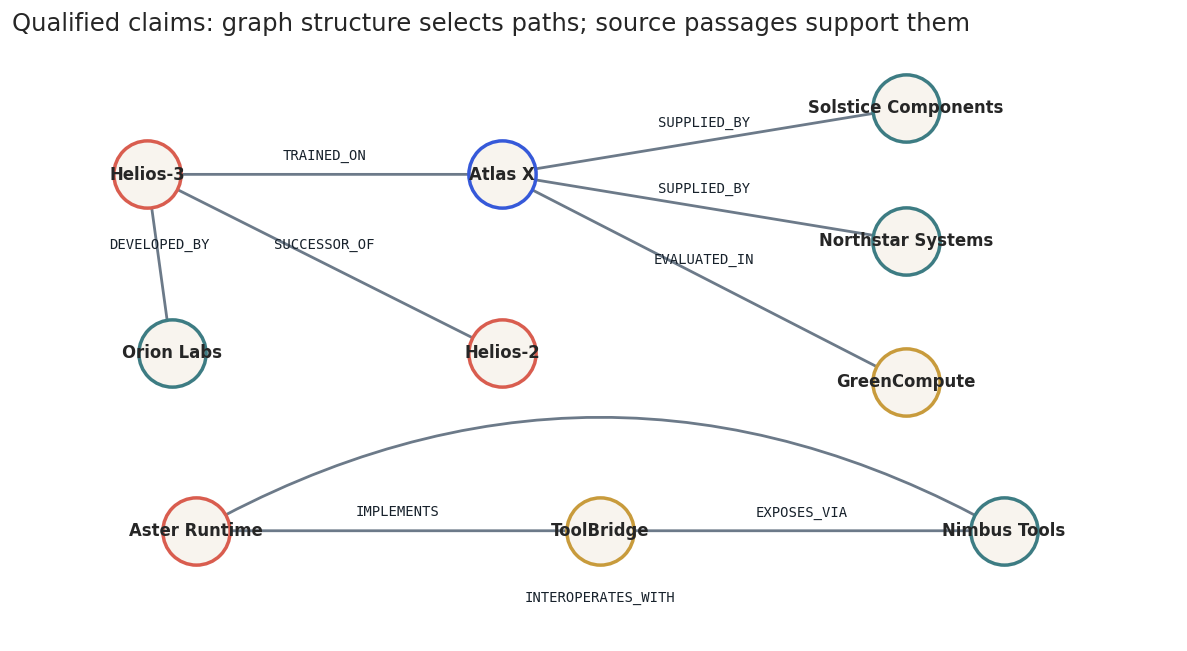

In [14]:
# A compact, editable graph visual without an additional graph library.
positions = {
    "model:helios_3": (0.08, 0.68), "hardware:atlas_x": (0.37, 0.68),
    "org:solstice": (0.70, 0.84), "org:northstar": (0.70, 0.52),
    "org:orion": (0.10, 0.25), "model:helios_2": (0.37, 0.25),
    "benchmark:greencompute": (0.70, 0.18), "software:aster": (0.12, -0.18),
    "standard:toolbridge": (0.45, -0.18), "service:nimbus": (0.78, -0.18),
}

type_colors = {
    "MODEL": PALETTE["coral"], "HARDWARE": PALETTE["cobalt"],
    "ORGANISATION": PALETTE["teal"], "SOFTWARE": PALETTE["coral"],
    "STANDARD": PALETTE["gold"], "SERVICE": PALETTE["teal"],
    "BENCHMARK": PALETTE["gold"],
}

fig, ax = plt.subplots(figsize=(12, 6.2))
ax.set_axis_off()
for edge in graph_edges:
    x1, y1 = positions[edge["source"]]
    x2, y2 = positions[edge["target"]]
    direct_agent_link = edge["edge_id"] == "E008"
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(
                    arrowstyle="->", color=PALETTE["slate"], lw=1.6,
                    connectionstyle="arc3,rad=-0.28" if direct_agent_link else "arc3,rad=0",
                ))
    label_y = (y1+y2)/2 + (-0.17 if direct_agent_link else 0.035)
    ax.text((x1+x2)/2, label_y, edge["relation"],
            ha="center", fontsize=8, family="monospace", color=PALETTE["ink"])
for entity in entities:
    x, y = positions[entity["entity_id"]]
    ax.scatter([x], [y], s=1500, facecolor=PALETTE["paper"],
               edgecolor=type_colors[entity["type"]], linewidth=2, zorder=3)
    ax.text(x, y, entity["label"], ha="center", va="center",
            fontsize=9.5, weight="bold", zorder=4)
ax.set_xlim(-0.03, 0.92)
ax.set_ylim(-0.44, 1.0)
ax.set_title("Qualified claims: graph structure selects paths; source passages support them", loc="left", fontsize=14)
plt.show()

**What the graph does not contain matters.** The sentence “Quanta Agents does not implement ToolBridge” is not stored as a positive `IMPLEMENTS` edge. Absence of an edge does not by itself mean that the relation is false; explicit negation needs its own representation or source-text verification.

Likewise, `P013` co-mentions Northstar and Atlas X but explicitly denies that it describes a supply relation. A co-occurrence graph could connect them. This knowledge graph does not.

# 6 · Link query entities and expand controlled neighbourhoods

🔴 **CORE · Course 6**

In [15]:
# Longest-alias-first linking. Production entity linking must also model ambiguity and NIL cases.
alias_to_entity = {}
for entity in entities:
    for alias in entity["aliases"]:
        alias_to_entity[normalize_text(alias)] = entity["entity_id"]

sorted_aliases = sorted(alias_to_entity, key=lambda value: (-len(value.split()), -len(value), value))


def link_query_entities(query: str) -> list[dict]:
    normalized = f" {normalize_text(query)} "
    matches = []
    occupied = []
    for alias in sorted_aliases:
        pattern = r"(?<![a-z0-9])" + re.escape(alias) + r"(?![a-z0-9])"
        match = re.search(pattern, normalized)
        if not match:
            continue
        span = match.span()
        if any(not (span[1] <= start or span[0] >= end) for start, end in occupied):
            continue
        occupied.append(span)
        entity_id = alias_to_entity[alias]
        matches.append({
            "mention": alias,
            "entity_id": entity_id,
            "label": entity_by_id[entity_id]["label"],
            "type": entity_by_id[entity_id]["type"],
        })
    return matches


link_examples = [
    "Which company supplied Atlas-X for the 2026 run?",
    "Which standard connects Aster Runtime to Nimbus Tools?",
    "What did an Atlas accelerator benchmark show?",
]
for query in link_examples:
    print("\nQUERY:", query)
    print(pd.DataFrame(link_query_entities(query)).to_string(index=False))


QUERY: Which company supplied Atlas-X for the 2026 run?
mention        entity_id   label     type
atlas x hardware:atlas_x Atlas X HARDWARE

QUERY: Which standard connects Aster Runtime to Nimbus Tools?
      mention      entity_id         label     type
aster runtime software:aster Aster Runtime SOFTWARE
 nimbus tools service:nimbus  Nimbus Tools  SERVICE

QUERY: What did an Atlas accelerator benchmark show?
          mention        entity_id   label     type
atlas accelerator hardware:atlas_x Atlas X HARDWARE


The linker maps surface forms such as `Atlas-X` and `Atlas accelerator` to the same canonical entity. That can recover evidence hidden behind aliases—but a wrong link narrows retrieval to the wrong neighbourhood with high confidence.

This baseline intentionally returns an empty list for unknown entities. **NIL is a valid result.** A production system should not force every mention onto an existing node.

In [16]:
def query_window(question_record: dict | None, query: str) -> tuple[date, date] | None:
    if question_record and question_record.get("time_scope"):
        start, end = question_record["time_scope"]
        return date.fromisoformat(start), date.fromisoformat(end)
    years = sorted({int(y) for y in re.findall(r"\b(?:19|20)\d{2}\b", query)})
    if not years:
        return None
    return date(years[0], 1, 1), date(years[-1], 12, 31)


def interval_overlaps(edge: dict, window: tuple[date, date] | None) -> bool:
    if window is None:
        return True
    query_start, query_end = window
    edge_start = date.fromisoformat(edge["valid_from"]) if edge.get("valid_from") else date.min
    edge_end = date.fromisoformat(edge["valid_to"]) if edge.get("valid_to") else date.max
    return edge_start <= query_end and edge_end >= query_start


def graph_evidence(
    query: str,
    question_record: dict | None = None,
    max_hops: int = 2,
    time_aware: bool = False,
    edge_list: list[dict] | None = None,
) -> dict:
    edge_list = edge_list or graph_edges
    seeds = [m["entity_id"] for m in link_query_entities(query)]
    window = query_window(question_record, query) if time_aware else None

    incident = defaultdict(list)
    for edge in edge_list:
        incident[edge["source"]].append(edge)
        incident[edge["target"]].append(edge)

    queue = deque((seed, 0, entity_by_id[seed]["label"]) for seed in seeds)
    best_depth = {seed: 0 for seed in seeds}
    evidence = {}
    edges_examined = 0
    edges_filtered_by_time = 0

    while queue:
        node, depth, path_text = queue.popleft()
        if depth >= max_hops:
            continue
        for edge in incident[node]:
            edges_examined += 1
            if time_aware and not interval_overlaps(edge, window):
                edges_filtered_by_time += 1
                continue

            forward = edge["source"] == node
            neighbour = edge["target"] if forward else edge["source"]
            relation_text = f"--{edge['relation']}-->" if forward else f"<--{edge['relation']}--"
            next_path = f"{path_text} {relation_text} {entity_by_id[neighbour]['label']} [{edge['evidence']}]"
            hop = depth + 1
            bonus = 1.25 / hop
            pid = edge["evidence"]
            existing = evidence.get(pid)
            if existing is None or bonus > existing["graph_bonus"]:
                evidence[pid] = {
                    "passage_id": pid,
                    "graph_bonus": bonus,
                    "hop": hop,
                    "path": next_path,
                    "edge_id": edge["edge_id"],
                }

            if hop < max_hops and (neighbour not in best_depth or hop < best_depth[neighbour]):
                best_depth[neighbour] = hop
                queue.append((neighbour, hop, next_path))

    return {
        "linked_entities": seeds,
        "window": window,
        "evidence": list(evidence.values()),
        "edges_examined": edges_examined,
        "edges_filtered_by_time": edges_filtered_by_time,
    }

In [17]:
# Compare the same 2025 query with and without temporal validity filtering.
temporal_q = question_by_id["Q04"]
for aware in [False, True]:
    result = graph_evidence(
        temporal_q["question"], question_record=temporal_q,
        max_hops=2, time_aware=aware,
    )
    frame = pd.DataFrame(result["evidence"])
    print("\nTIME AWARE =", aware, "· filtered edges =", result["edges_filtered_by_time"])
    display(frame[["passage_id", "hop", "graph_bonus", "path"]] if not frame.empty else frame)


TIME AWARE = False · filtered edges = 0

TIME AWARE = True · filtered edges = 3


,passage_id,hop,graph_bonus,path
0,P002,1,1.250,Atlas X <--TRAINED_ON-- Helios-3 [P002]
1,P003,1,1.250,Atlas X --SUPPLIED_BY--> Solstice Components [P003]
2,P004,1,1.250,Atlas X --SUPPLIED_BY--> Northstar Systems [P004]
3,P005,1,1.250,Atlas X --EVALUATED_IN--> GreenCompute [P005]
4,P006,2,0.625,Atlas X <--TRAINED_ON-- Helios-3 [P002] --DEVELOPED_BY--> Orion Labs [P006]


,passage_id,hop,graph_bonus,path
0,P004,1,1.25,Atlas X --SUPPLIED_BY--> Northstar Systems [P004]


Time-aware expansion removes the 2026 supplier edge for a 2025 question. It does not “know the answer”; it enforces an explicit validity constraint.

The distinction is important:

- **publication filtering** asks when a source was published;
- **claim-validity filtering** asks when the relationship held;
- **question time** asks which interval the user is asking about.

Conflating these timestamps produces plausible but temporally wrong answers.

# 7 · Build the graph-enhanced retrievers

🔴 **CORE**

We now combine BM25 with graph evidence. The graph contributes a transparent bonus; it does not replace text ranking.

Two variants expose an important design choice:

- `GRAPH_ALWAYS`: expand whenever a query contains a known entity, without time filtering;
- `GRAPH_ROUTED_TIME`: expand only when the question expresses a relational/temporal need, and filter edges by validity.

This is not a claim that the scoring formula is optimal. It is a small, inspectable experiment that makes the causal intervention visible.

In [18]:
GRAPH_CUES = (
    "supplied", "supplier", "used to train", "connects",
    "relationship", "change from", "under the 2025", "for the 2026 run",
)


def route_query(query: str) -> str:
    normalized = normalize_text(query)
    return "graph" if any(cue in normalized for cue in GRAPH_CUES) else "text"


def graph_retrieve(
    query: str,
    top_k: int = TOP_K,
    question_record: dict | None = None,
    route: bool = False,
    time_aware: bool = False,
    max_hops: int = 2,
    edge_list: list[dict] | None = None,
) -> list[dict]:
    selected_route = route_query(query) if route else "graph"
    if selected_route == "text":
        rows = text_retrieve(query, top_k=top_k)
        for row in rows:
            row["route"] = "text-routed"
            row["reason"] = "router chose text"
        return rows

    text_scores = bm25.scores(query)
    max_text = float(text_scores.max()) or 1.0
    evidence_result = graph_evidence(
        query,
        question_record=question_record,
        max_hops=max_hops,
        time_aware=time_aware,
        edge_list=edge_list,
    )
    graph_by_pid = {item["passage_id"]: item for item in evidence_result["evidence"]}

    candidates = []
    for i, passage in enumerate(passages):
        pid = passage["passage_id"]
        normalized_text_score = float(text_scores[i] / max_text)
        graph_item = graph_by_pid.get(pid)
        graph_bonus = graph_item["graph_bonus"] if graph_item else 0.0
        combined = normalized_text_score + graph_bonus
        reason = graph_item["path"] if graph_item else "BM25 only"
        candidates.append({
            "passage_id": pid,
            "score": combined,
            "text_score": normalized_text_score,
            "graph_bonus": graph_bonus,
            "route": "graph+routed" if route else "graph+always",
            "reason": reason,
            "title": passage["title"],
            "text": passage["text"],
            "edges_examined": evidence_result["edges_examined"],
            "edges_filtered_by_time": evidence_result["edges_filtered_by_time"],
        })

    candidates.sort(key=lambda row: (-row["score"], row["passage_id"]))
    rows = candidates[:top_k]
    for rank, row in enumerate(rows, start=1):
        row["rank"] = rank
    return rows


def graph_always_retrieve(query: str, top_k: int = TOP_K, question_record=None, **_kwargs):
    return graph_retrieve(
        query, top_k=top_k, question_record=question_record,
        route=False, time_aware=False, max_hops=2,
    )


def graph_routed_time_retrieve(query: str, top_k: int = TOP_K, question_record=None, **_kwargs):
    return graph_retrieve(
        query, top_k=top_k, question_record=question_record,
        route=True, time_aware=True, max_hops=2,
    )


print("Q01 route:", route_query(question_by_id["Q01"]["question"]))
print("Q03 route:", route_query(question_by_id["Q03"]["question"]))
print("Q10 route:", route_query(question_by_id["Q10"]["question"]))

Q01 route: text
Q03 route: graph
Q10 route: graph


In [19]:
# Inspect one relational success across all three systems.
q = question_by_id["Q03"]
for name, retriever in [
    ("TEXT", text_retrieve),
    ("GRAPH_ALWAYS", graph_always_retrieve),
    ("GRAPH_ROUTED_TIME", graph_routed_time_retrieve),
]:
    print("\n", name)
    display(ranking_frame(retriever(q["question"], question_record=q)))


 TEXT

 GRAPH_ALWAYS

 GRAPH_ROUTED_TIME


,rank,passage_id,score,text_score,graph_bonus,route,reason,title,text
0,1,P003,5.337,5.337,0.0,text,BM25,Atlas X supply for the 2026 run,Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.
1,2,P001,4.643,4.643,0.0,text,BM25,Helios-3 preview scheduled,Orion Labs said Helios-3 will enter public preview in October 2026.
2,3,P012,3.953,3.953,0.0,text,BM25,Solstice expands production,"Solstice Components, also known as Solstice, expanded accelerator production in Basel."


,rank,passage_id,score,text_score,graph_bonus,route,reason,title,text
0,1,P006,1.845,0.595,1.250,graph+always,Helios-3 --DEVELOPED_BY--> Orion Labs [P006],The Helios model family,Orion Labs developed Helios-3 from the earlier Helios-2 family.
1,2,P003,1.625,1.000,0.625,graph+always,Helios-3 --TRAINED_ON--> Atlas X [P002] --SUPPLIED_BY--> Solstice Components [P003],Atlas X supply for the 2026 run,Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.
2,3,P002,1.568,0.318,1.250,graph+always,Helios-3 --TRAINED_ON--> Atlas X [P002],Helios-3 training infrastructure,Orion Labs reported that Helios-3 was trained on Atlas X accelerators.


,rank,passage_id,score,text_score,graph_bonus,route,reason,title,text
0,1,P006,1.845,0.595,1.250,graph+routed,Helios-3 --DEVELOPED_BY--> Orion Labs [P006],The Helios model family,Orion Labs developed Helios-3 from the earlier Helios-2 family.
1,2,P003,1.625,1.000,0.625,graph+routed,Helios-3 --TRAINED_ON--> Atlas X [P002] --SUPPLIED_BY--> Solstice Components [P003],Atlas X supply for the 2026 run,Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.
2,3,P002,1.568,0.318,1.250,graph+routed,Helios-3 --TRAINED_ON--> Atlas X [P002],Helios-3 training infrastructure,Orion Labs reported that Helios-3 was trained on Atlas X accelerators.


In [20]:
# Inspect a direct factual question where graph expansion adds no clear value.
q = question_by_id["Q01"]
for name, retriever in [
    ("TEXT", text_retrieve),
    ("GRAPH_ALWAYS", graph_always_retrieve),
    ("GRAPH_ROUTED_TIME", graph_routed_time_retrieve),
]:
    print("\n", name)
    display(ranking_frame(retriever(q["question"], question_record=q)))


 TEXT

 GRAPH_ALWAYS

 GRAPH_ROUTED_TIME


,rank,passage_id,score,text_score,graph_bonus,route,reason,title,text
0,1,P001,7.317,7.317,0.0,text,BM25,Helios-3 preview scheduled,Orion Labs said Helios-3 will enter public preview in October 2026.
1,2,P011,5.605,5.605,0.0,text,BM25,Helios-3 enters public preview,Helios-3 entered public preview on 8 October 2026.
2,3,P014,4.027,4.027,0.0,text,BM25,Undisclosed training details,Orion Labs did not disclose exact training energy consumption for Helios-3.


,rank,passage_id,score,text_score,graph_bonus,route,reason,title,text
0,1,P006,1.539,0.289,1.25,graph+always,Helios-3 --DEVELOPED_BY--> Orion Labs [P006],The Helios model family,Orion Labs developed Helios-3 from the earlier Helios-2 family.
1,2,P002,1.482,0.232,1.25,graph+always,Helios-3 --TRAINED_ON--> Atlas X [P002],Helios-3 training infrastructure,Orion Labs reported that Helios-3 was trained on Atlas X accelerators.
2,3,P001,1.000,1.000,0.00,graph+always,BM25 only,Helios-3 preview scheduled,Orion Labs said Helios-3 will enter public preview in October 2026.


,rank,passage_id,score,text_score,graph_bonus,route,reason,title,text
0,1,P001,7.317,7.317,0.0,text-routed,router chose text,Helios-3 preview scheduled,Orion Labs said Helios-3 will enter public preview in October 2026.
1,2,P011,5.605,5.605,0.0,text-routed,router chose text,Helios-3 enters public preview,Helios-3 entered public preview on 8 October 2026.
2,3,P014,4.027,4.027,0.0,text-routed,router chose text,Undisclosed training details,Orion Labs did not disclose exact training energy consumption for Helios-3.


The “always expand” variant is intentionally naïve. For a direct preview-date question, entity expansion can pull in training, supplier, developer, and benchmark passages simply because they are near `Helios-3` in the graph.

The routed variant declines to use the graph. **No graph** is a legitimate retrieval decision when text already matches the information need.

# 8 · Compare retrieval systems by question category

🔴 **CORE**

In [21]:
retrievers = {
    "TEXT": text_retrieve,
    "GRAPH_ALWAYS": graph_always_retrieve,
    "GRAPH_ROUTED_TIME": graph_routed_time_retrieve,
}

retrieval_results = pd.concat(
    [evaluate_retriever(name, retriever) for name, retriever in retrievers.items()],
    ignore_index=True,
)
display(retrieval_results)

,system,question_id,category,required,retrieved,evidence_recall@k,complete_evidence@k,first_relevant_rr,context_precision@k
0,TEXT,Q01,factual,[P011],"[P001, P011, P014]",1.0,1.0,0.500000,0.333333
1,TEXT,Q02,factual,[P001],"[P011, P001, P002]",1.0,1.0,0.500000,0.333333
2,TEXT,Q03,relational,"[P002, P003]","[P003, P001, P012]",0.5,0.0,1.000000,0.333333
3,TEXT,Q04,temporal,[P004],"[P003, P004, P005]",1.0,1.0,0.500000,0.333333
4,TEXT,Q05,entity-centric,[P003],"[P003, P005, P007]",1.0,1.0,1.000000,0.333333
5,TEXT,Q06,relational,"[P007, P008]","[P009, P007, P008]",1.0,1.0,0.500000,0.666667
6,TEXT,Q07,factual,[P006],"[P006, P011, P001]",1.0,1.0,1.000000,0.333333
7,TEXT,Q08,unanswerable,[],"[P014, P006, P003]",NaN,NaN,NaN,NaN
8,TEXT,Q09,negation,[P010],"[P010, P007, P008]",1.0,1.0,1.000000,0.333333
9,TEXT,Q10,comparative-temporal,"[P004, P003]","[P004, P005, P013]",0.5,0.0,1.000000,0.333333


In [22]:
retrieval_summary = (
    retrieval_results.dropna(subset=["evidence_recall@k"])
    .groupby("system")
    .agg(
        evidence_recall=("evidence_recall@k", "mean"),
        complete_evidence=("complete_evidence@k", "mean"),
        context_precision=("context_precision@k", "mean"),
        first_relevant_rr=("first_relevant_rr", "mean"),
    )
    .reset_index()
)
display(retrieval_summary.round(3))

category_summary = (
    retrieval_results.dropna(subset=["evidence_recall@k"])
    .groupby(["system", "category"])
    .agg(
        n=("question_id", "count"),
        evidence_recall=("evidence_recall@k", "mean"),
        complete_evidence=("complete_evidence@k", "mean"),
        context_precision=("context_precision@k", "mean"),
    )
    .reset_index()
)
display(category_summary.round(3))

,system,evidence_recall,complete_evidence,context_precision,first_relevant_rr
0,GRAPH_ALWAYS,0.8,0.8,0.367,0.583
1,GRAPH_ROUTED_TIME,1.0,1.0,0.433,0.800
2,TEXT,0.9,0.8,0.367,0.800


,system,category,n,evidence_recall,complete_evidence,context_precision
0,GRAPH_ALWAYS,comparative-temporal,1,1.00,1.0,0.667
1,GRAPH_ALWAYS,entity-centric,1,1.00,1.0,0.333
2,GRAPH_ALWAYS,factual,4,0.50,0.5,0.167
3,GRAPH_ALWAYS,negation,1,1.00,1.0,0.333
4,GRAPH_ALWAYS,relational,2,1.00,1.0,0.667
5,GRAPH_ALWAYS,temporal,1,1.00,1.0,0.333
6,GRAPH_ROUTED_TIME,comparative-temporal,1,1.00,1.0,0.667
7,GRAPH_ROUTED_TIME,entity-centric,1,1.00,1.0,0.333
8,GRAPH_ROUTED_TIME,factual,4,1.00,1.0,0.333
9,GRAPH_ROUTED_TIME,negation,1,1.00,1.0,0.333


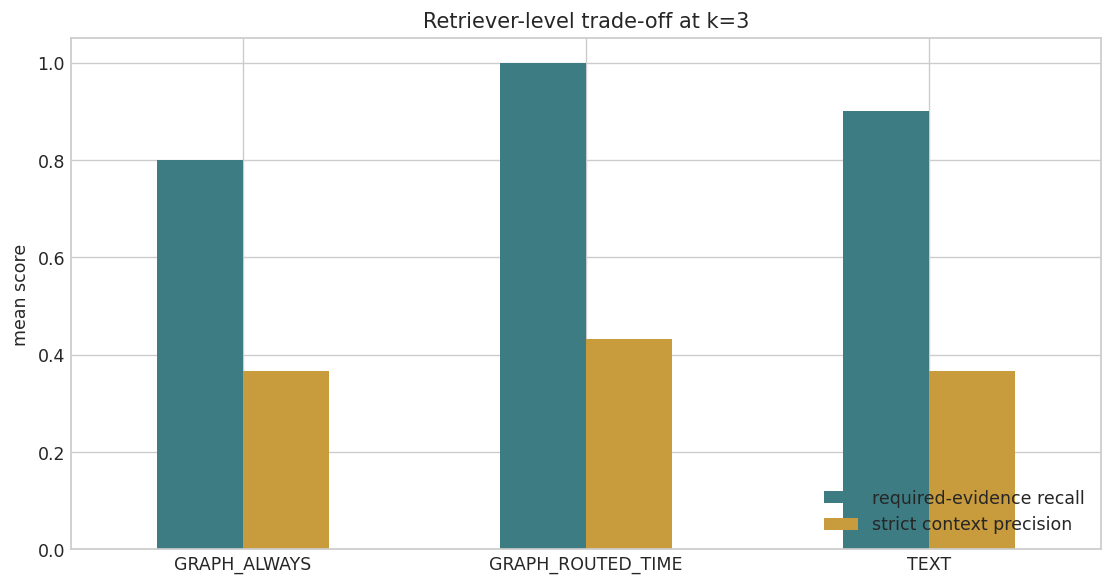

In [23]:
# Visualise the central trade-off rather than only an overall winner.
plot_frame = retrieval_summary.set_index("system")[["evidence_recall", "context_precision"]]
ax = plot_frame.plot(
    kind="bar", figsize=(9, 4.8), color=[PALETTE["teal"], PALETTE["gold"]],
    ylim=(0, 1.05), rot=0,
)
ax.set_title("Retriever-level trade-off at k=3")
ax.set_ylabel("mean score")
ax.set_xlabel("")
ax.legend(["required-evidence recall", "strict context precision"], loc="lower right")
plt.tight_layout()
plt.show()

◇ **CHECKPOINT — interpret, do not declare a universal winner**

Discuss these questions:

1. Which categories gained complete evidence?
2. Where did graph expansion reduce context precision?
3. Did routing preserve direct factual performance?
4. Would the conclusion change at `k=5`?
5. What graph-quality error would invalidate the result?

Report category-level results in the capstone. A small overall average can hide a large gain on relational questions and a loss on factual ones.

# 9 · Assemble RAG evidence packets

🔴 **CORE · graph + source text**

Graph structure and source text play complementary roles:

- the graph selects entities, edges, paths, and candidate passages;
- source passages preserve wording, attribution, negation, dates, and qualifiers;
- the answerer receives passages with stable IDs—not unsupported triples alone.

The context packet below is intentionally auditable. A production packet should also retain scores, index version, graph version, filters, latency, and prompt/model metadata.

In [24]:
def build_context_packet(question_record: dict, retriever, top_k: int = TOP_K) -> dict:
    rows = retriever(
        question_record["question"],
        top_k=top_k,
        question_record=question_record,
    )
    selected = []
    rendered = []
    for row in rows:
        passage = passage_by_id[row["passage_id"]]
        item = {
            "rank": row["rank"],
            "passage_id": passage["passage_id"],
            "source": passage["source"],
            "published_at": passage["published_at"],
            "claim_valid_from": passage["claim_valid_from"],
            "claim_valid_to": passage["claim_valid_to"],
            "score": row["score"],
            "route": row["route"],
            "reason": row["reason"],
            "text": passage["text"],
        }
        selected.append(item)
        rendered.append(
            f"[{item['passage_id']} | {item['source']} | {item['published_at']}] {item['text']}"
        )
    return {
        "question_id": question_record["question_id"],
        "question": question_record["question"],
        "passages": selected,
        "context": "\n\n".join(rendered),
    }


q = question_by_id["Q03"]
text_packet = build_context_packet(q, text_retrieve)
graph_packet = build_context_packet(q, graph_routed_time_retrieve)

print("TEXT PACKET\n", text_packet["context"])
print("\nGRAPH-ENHANCED PACKET\n", graph_packet["context"])

TEXT PACKET
 [P003 | Compute Wire | 2026-05-20] Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.

[P001 | AI Ledger | 2026-09-14] Orion Labs said Helios-3 will enter public preview in October 2026.

[P012 | Industry Signal | 2026-05-21] Solstice Components, also known as Solstice, expanded accelerator production in Basel.

GRAPH-ENHANCED PACKET
 [P006 | Model Observer | 2026-08-23] Orion Labs developed Helios-3 from the earlier Helios-2 family.

[P003 | Compute Wire | 2026-05-20] Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.

[P002 | Compute Wire | 2026-05-12] Orion Labs reported that Helios-3 was trained on Atlas X accelerators.


### A fixed answerer isolates retrieval effects

The next function is a transparent **extractive proxy**, not a production LLM. It uses the same frozen rules for every retrieval system and never reads `reference_answer` or `required_evidence`.

Why use it?

- the notebook remains reproducible without an API key;
- answer changes can be traced to context changes;
- students can inspect citation and abstention behaviour;
- an LLM can later replace this component through the same interface.

Its scores are teaching diagnostics, not claims about model quality.

In [25]:
def packet_has(packet: dict, passage_id: str) -> bool:
    return any(p["passage_id"] == passage_id for p in packet["passages"])


def fixed_evidence_answerer(question_record: dict, packet: dict) -> dict:
    task = question_record["answer_task"]
    text = " ".join(p["text"] for p in packet["passages"])
    citations = []
    answer = "Insufficient evidence in the retrieved context."

    if task == "preview_actual":
        match = re.search(r"entered public preview on ([0-9]{1,2} [A-Za-z]+ 20[0-9]{2})", text)
        if match:
            answer = f"Helios-3 entered public preview on {match.group(1)}."
            citations = ["P011"] if packet_has(packet, "P011") else []

    elif task == "preview_scheduled":
        match = re.search(r"public preview in ([A-Za-z]+ 20[0-9]{2})", text)
        if match:
            answer = f"The preview was scheduled for {match.group(1)}."
            citations = ["P001"] if packet_has(packet, "P001") else []

    elif task in {"supplier_2026_chain", "supplier_2026_direct"}:
        if "Solstice Components supplied Atlas X" in text:
            answer = "Solstice Components supplied the Atlas X units for the 2026 run."
            if task == "supplier_2026_chain" and packet_has(packet, "P002"):
                citations.append("P002")
            if packet_has(packet, "P003"):
                citations.append("P003")

    elif task == "supplier_2025":
        if "Northstar Systems began supplying Atlas X" in text:
            answer = "Northstar Systems supplied Atlas X under the 2025 agreement."
            citations = ["P004"] if packet_has(packet, "P004") else []

    elif task == "agent_standard":
        if "ToolBridge" in text:
            answer = "ToolBridge is the standard connecting Aster Runtime and Nimbus Tools."
            citations = [pid for pid in ["P007", "P008"] if packet_has(packet, pid)]

    elif task == "developer":
        if "Orion Labs developed Helios-3" in text:
            answer = "Orion Labs developed Helios-3."
            citations = ["P006"] if packet_has(packet, "P006") else []

    elif task == "parameter_count":
        answer = "Insufficient evidence in the retrieved context."

    elif task == "quanta_negation":
        if "does not implement ToolBridge" in text:
            answer = "No. Quanta Agents does not implement ToolBridge."
            citations = ["P010"] if packet_has(packet, "P010") else []

    elif task == "supplier_change":
        has_2025 = "Northstar Systems began supplying Atlas X" in text
        has_2026 = "Solstice Components supplied Atlas X" in text
        if has_2025 and has_2026:
            answer = "Northstar Systems supplied Atlas X in 2025; Solstice Components supplied it in 2026."
            citations = [pid for pid in ["P004", "P003"] if packet_has(packet, pid)]
        elif has_2025:
            answer = "Northstar Systems supplied Atlas X in 2025; the retrieved context does not establish the 2026 supplier."
            citations = ["P004"]
        elif has_2026:
            answer = "Solstice Components supplied Atlas X in 2026; the retrieved context does not establish the 2025 supplier."
            citations = ["P003"]

    elif task == "benchmark":
        if "GreenCompute efficiency benchmark" in text:
            answer = "Atlas X led the GreenCompute efficiency benchmark."
            citations = ["P005"] if packet_has(packet, "P005") else []

    return {"answer": answer, "citations": citations}


for packet_name, packet in [("TEXT", text_packet), ("GRAPH_ROUTED_TIME", graph_packet)]:
    output = fixed_evidence_answerer(q, packet)
    print(packet_name, "→", output)

TEXT → {'answer': 'Solstice Components supplied the Atlas X units for the 2026 run.', 'citations': ['P003']}
GRAPH_ROUTED_TIME → {'answer': 'Solstice Components supplied the Atlas X units for the 2026 run.', 'citations': ['P002', 'P003']}


In [26]:
def build_grounded_prompt(question_record: dict, packet: dict) -> str:
    return (
        "You answer only from the evidence passages below.\n\n"
        "Rules:\n"
        "- Cite passage IDs in square brackets after each supported claim.\n"
        "- Preserve dates, negation, uncertainty, and attribution.\n"
        "- If the passages are insufficient or conflicting, say so explicitly.\n"
        "- Do not treat a graph path as evidence unless its linked passage is present.\n\n"
        f"Question:\n{question_record['question']}\n\n"
        f"Evidence:\n{packet['context']}\n\n"
        "Return:\n"
        "1. concise answer\n"
        "2. supporting passage IDs\n"
        "3. one-sentence qualification or abstention reason, if needed"
    )


print(build_grounded_prompt(q, graph_packet))

You answer only from the evidence passages below.

Rules:
- Cite passage IDs in square brackets after each supported claim.
- Preserve dates, negation, uncertainty, and attribution.
- If the passages are insufficient or conflicting, say so explicitly.
- Do not treat a graph path as evidence unless its linked passage is present.

Question:
Who supplied the accelerator used to train Helios-3 in 2026?

Evidence:
[P006 | Model Observer | 2026-08-23] Orion Labs developed Helios-3 from the earlier Helios-2 family.

[P003 | Compute Wire | 2026-05-20] Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.

[P002 | Compute Wire | 2026-05-12] Orion Labs reported that Helios-3 was trained on Atlas X accelerators.

Return:
1. concise answer
2. supporting passage IDs
3. one-sentence qualification or abstention reason, if needed


↗ **Optional LLM bridge**

Replace `fixed_evidence_answerer(question_record, packet)` with your current provider or local-model call. Keep the function contract:

```python
{"answer": "...", "citations": ["P002", "P003"]}
```

Record model identifier, prompt version, decoding settings, call time, and raw response. Use structured output where helpful, but remember: schema validity does not guarantee that the answer is supported.

The notebook deliberately avoids a live API dependency so that the retrieval experiment remains reproducible and teachable.

# 10 · Evaluate retrieval, context, and answers separately

🔴 **CORE**

In [27]:
def passage_overlaps_question_time(passage: dict, question_record: dict) -> bool:
    window = query_window(question_record, question_record["question"])
    if window is None:
        return True
    if not passage.get("claim_valid_from") and not passage.get("claim_valid_to"):
        return True  # no claim-validity assertion to contradict the question time
    start = date.fromisoformat(passage["claim_valid_from"]) if passage.get("claim_valid_from") else date.min
    end = date.fromisoformat(passage["claim_valid_to"]) if passage.get("claim_valid_to") else date.max
    return start <= window[1] and end >= window[0]


def context_metrics(question_record: dict, packet: dict) -> dict:
    retrieved = [p["passage_id"] for p in packet["passages"]]
    required = set(question_record["required_evidence"])
    hits = len(required.intersection(retrieved))
    recall = hits / len(required) if required else np.nan
    precision = hits / len(retrieved) if retrieved and required else np.nan
    sufficient = float(required.issubset(retrieved)) if required else np.nan

    temporal_claims = [
        p for p in packet["passages"]
        if p.get("claim_valid_from") or p.get("claim_valid_to")
    ]
    current = [p for p in temporal_claims if passage_overlaps_question_time(p, question_record)]
    temporal_precision = len(current) / len(temporal_claims) if temporal_claims else 1.0
    return {
        "context_recall": recall,
        "context_precision": precision,
        "context_sufficient": sufficient,
        "temporal_context_precision": temporal_precision,
        "stale_or_out_of_scope_passages": [
            p["passage_id"] for p in temporal_claims
            if not passage_overlaps_question_time(p, question_record)
        ],
    }


def normalized_answer(text: str) -> str:
    return normalize_text(re.sub(r"[^A-Za-z0-9 -]+", " ", text))


def answer_metrics(question_record: dict, packet: dict, output: dict) -> dict:
    answer_norm = normalized_answer(output["answer"])
    citations = output["citations"]
    packet_ids = {p["passage_id"] for p in packet["passages"]}
    required = set(question_record["required_evidence"])
    abstained = answer_norm.startswith("insufficient evidence")

    correct = float(all(key in answer_norm for key in question_record["answer_keys"]))
    citation_valid = float(set(citations).issubset(packet_ids))
    citation_complete = (
        len(required.intersection(citations)) / len(required)
        if required else float(abstained)
    )
    # Minimal automated faithfulness proxy: cited evidence is present and contains
    # every answer key. Human review remains the anchor.
    cited_text = " ".join(passage_by_id[pid]["text"] for pid in citations if pid in passage_by_id)
    cited_norm = normalized_answer(cited_text)
    faithful_proxy = float(
        abstained or (
            bool(citations)
            and citation_valid == 1
            and all(key in cited_norm for key in question_record["answer_keys"])
        )
    )
    temporal_grounding = float(
        all(passage_overlaps_question_time(passage_by_id[pid], question_record) for pid in citations)
    ) if citations else float(abstained)
    abstention_correct = float(abstained == (not question_record["answerable"]))
    return {
        "answer_correct": correct,
        "faithful_proxy": faithful_proxy,
        "citation_valid": citation_valid,
        "citation_completeness": citation_complete,
        "temporal_grounding": temporal_grounding,
        "abstention_correct": abstention_correct,
    }

In [28]:
def evaluate_end_to_end(system_name: str, retriever) -> pd.DataFrame:
    records = []
    for q in questions:
        start = time.perf_counter()
        packet = build_context_packet(q, retriever)
        retrieval_ms = (time.perf_counter() - start) * 1000
        output = fixed_evidence_answerer(q, packet)
        c_metrics = context_metrics(q, packet)
        a_metrics = answer_metrics(q, packet, output)
        records.append({
            "system": system_name,
            "question_id": q["question_id"],
            "category": q["category"],
            "retrieved": [p["passage_id"] for p in packet["passages"]],
            "answer": output["answer"],
            "citations": output["citations"],
            "retrieval_ms_local": retrieval_ms,
            **c_metrics,
            **a_metrics,
        })
    return pd.DataFrame(records)


end_to_end = pd.concat(
    [evaluate_end_to_end(name, retriever) for name, retriever in retrievers.items()],
    ignore_index=True,
)
display(end_to_end)

,system,question_id,category,retrieved,answer,citations,retrieval_ms_local,context_recall,context_precision,context_sufficient,temporal_context_precision,stale_or_out_of_scope_passages,answer_correct,faithful_proxy,citation_valid,citation_completeness,temporal_grounding,abstention_correct
0,TEXT,Q01,factual,"[P001, P011, P014]",Helios-3 entered public preview on 8 October 2026.,[P011],0.075024,1.0,0.333333,1.0,1.000000,[],1.0,1.0,1.0,1.0,1.0,1.0
1,TEXT,Q02,factual,"[P011, P001, P002]",The preview was scheduled for October 2026.,[P001],0.056225,1.0,0.333333,1.0,1.000000,[],1.0,1.0,1.0,1.0,1.0,1.0
2,TEXT,Q03,relational,"[P003, P001, P012]",Solstice Components supplied the Atlas X units for the 2026 run.,[P003],0.050476,0.5,0.333333,0.0,1.000000,[],1.0,1.0,1.0,0.5,1.0,1.0
3,TEXT,Q04,temporal,"[P003, P004, P005]",Northstar Systems supplied Atlas X under the 2025 agreement.,[P004],0.038098,1.0,0.333333,1.0,0.333333,"[P003, P005]",1.0,1.0,1.0,1.0,1.0,1.0
4,TEXT,Q05,entity-centric,"[P003, P005, P007]",Solstice Components supplied the Atlas X units for the 2026 run.,[P003],0.067802,1.0,0.333333,1.0,1.000000,[],1.0,1.0,1.0,1.0,1.0,1.0
5,TEXT,Q06,relational,"[P009, P007, P008]",ToolBridge is the standard connecting Aster Runtime and Nimbus Tools.,"[P007, P008]",0.033250,1.0,0.666667,1.0,1.000000,[],1.0,1.0,1.0,1.0,1.0,1.0
6,TEXT,Q07,factual,"[P006, P011, P001]",Orion Labs developed Helios-3.,[P006],0.026791,1.0,0.333333,1.0,1.000000,[],1.0,1.0,1.0,1.0,1.0,1.0
7,TEXT,Q08,unanswerable,"[P014, P006, P003]",Insufficient evidence in the retrieved context.,[],0.034642,NaN,NaN,NaN,1.000000,[],1.0,1.0,1.0,1.0,1.0,1.0
8,TEXT,Q09,negation,"[P010, P007, P008]",No. Quanta Agents does not implement ToolBridge.,[P010],0.023285,1.0,0.333333,1.0,1.000000,[],1.0,1.0,1.0,1.0,1.0,1.0
9,TEXT,Q10,comparative-temporal,"[P004, P005, P013]",Northstar Systems supplied Atlas X in 2025; the retrieved context does not establish the 2026 supplier.,[P004],0.043075,0.5,0.333333,0.0,1.000000,[],0.0,0.0,1.0,0.5,1.0,1.0


In [29]:
metric_columns = [
    "context_recall", "context_precision", "context_sufficient",
    "temporal_context_precision", "answer_correct", "faithful_proxy",
    "citation_completeness", "temporal_grounding", "abstention_correct",
]
e2e_summary = end_to_end.groupby("system")[metric_columns].mean().reset_index()
display(e2e_summary.round(3))

by_category = (
    end_to_end.groupby(["system", "category"])[
        ["context_recall", "context_sufficient", "answer_correct", "citation_completeness"]
    ]
    .mean()
    .reset_index()
)
display(by_category.round(3))

,system,context_recall,context_precision,context_sufficient,temporal_context_precision,answer_correct,faithful_proxy,citation_completeness,temporal_grounding,abstention_correct
0,GRAPH_ALWAYS,0.8,0.367,0.8,0.909,0.818,1.000,0.818,1.0,0.818
1,GRAPH_ROUTED_TIME,1.0,0.433,1.0,0.939,1.000,1.000,1.000,1.0,1.000
2,TEXT,0.9,0.367,0.8,0.939,0.909,0.909,0.909,1.0,1.000


,system,category,context_recall,context_sufficient,answer_correct,citation_completeness
0,GRAPH_ALWAYS,comparative-temporal,1.00,1.0,1.0,1.00
1,GRAPH_ALWAYS,entity-centric,1.00,1.0,1.0,1.00
2,GRAPH_ALWAYS,factual,0.50,0.5,0.5,0.50
3,GRAPH_ALWAYS,negation,1.00,1.0,1.0,1.00
4,GRAPH_ALWAYS,relational,1.00,1.0,1.0,1.00
5,GRAPH_ALWAYS,temporal,1.00,1.0,1.0,1.00
6,GRAPH_ALWAYS,unanswerable,NaN,NaN,1.0,1.00
7,GRAPH_ROUTED_TIME,comparative-temporal,1.00,1.0,1.0,1.00
8,GRAPH_ROUTED_TIME,entity-centric,1.00,1.0,1.0,1.00
9,GRAPH_ROUTED_TIME,factual,1.00,1.0,1.0,1.00


### Read the layers in order

1. **Retriever:** did required evidence enter top-k?
2. **Context:** is the packet relevant, sufficient, non-redundant, and temporally valid?
3. **Answer:** is the response correct, supported, relevant, properly cited, and willing to abstain?

A correct answer with incomplete evidence is still a grounding failure. Conversely, perfect retrieval followed by an unsupported answer is a generation failure.

The automatic `faithful_proxy` above is intentionally narrow. Calibrate any automated judge against a human-reviewed sample, blind system identity where possible, and inspect disagreements rather than treating the score as ground truth.

In [30]:
# Show the controlled comparison for the two categories targeted by the hypothesis.
target_categories = {"relational", "temporal", "entity-centric", "comparative-temporal"}
hypothesis_view = (
    end_to_end[end_to_end["category"].isin(target_categories)]
    .groupby("system")
    .agg(
        context_recall=("context_recall", "mean"),
        context_sufficient=("context_sufficient", "mean"),
        citation_completeness=("citation_completeness", "mean"),
        answer_correct=("answer_correct", "mean"),
        temporal_context_precision=("temporal_context_precision", "mean"),
    )
    .reset_index()
)
display(hypothesis_view.round(3))

,system,context_recall,context_sufficient,citation_completeness,answer_correct,temporal_context_precision
0,GRAPH_ALWAYS,1.0,1.0,1.0,1.0,0.800
1,GRAPH_ROUTED_TIME,1.0,1.0,1.0,1.0,0.867
2,TEXT,0.8,0.6,0.8,0.8,0.867


◇ **CHECKPOINT — is the hypothesis supported?**

Use the table, not a general impression.

- Did complete context improve for the target categories?
- Did the routed system preserve performance on factual questions?
- Did temporal filtering remove expired relationships?
- Did answer correctness change less than citation completeness? Why?
- What additional evidence would you need before deploying the graph variant?

A defensible conclusion may be: **the graph helped a specific subgroup and improved evidence completeness, while adding indexing and maintenance cost.** That is more informative than “GraphRAG performed better.”

# 11 · Stress-test graph quality and failure propagation

↗ **EXTENSION**

One hallucinated or mislinked edge can create a plausible multi-hop path. We inject a false 2026 edge whose provenance passage explicitly says that no supply relationship was described.

This is a safe teaching stress test: the original graph remains unchanged.

In [31]:
bad_edge = {
    "edge_id": "E_BAD", "source": "hardware:atlas_x", "relation": "SUPPLIED_BY",
    "target": "org:northstar", "evidence": "P013",
    "valid_from": "2026-01-01", "valid_to": "2026-12-31", "confidence": 0.99,
}
corrupted_edges = graph_edges + [bad_edge]

q = question_by_id["Q03"]
corrupted_rows = graph_retrieve(
    q["question"], top_k=5, question_record=q,
    route=True, time_aware=True, max_hops=2, edge_list=corrupted_edges,
)
display(ranking_frame(corrupted_rows))
print("\nInjected evidence passage P013:\n", passage_by_id["P013"]["text"])


Injected evidence passage P013:
 An analyst note discussed Northstar Systems and Atlas X benchmark results without describing a supply relationship.


,rank,passage_id,score,text_score,graph_bonus,route,reason,title,text
0,1,P006,1.845,0.595,1.250,graph+routed,Helios-3 --DEVELOPED_BY--> Orion Labs [P006],The Helios model family,Orion Labs developed Helios-3 from the earlier Helios-2 family.
1,2,P003,1.625,1.000,0.625,graph+routed,Helios-3 --TRAINED_ON--> Atlas X [P002] --SUPPLIED_BY--> Solstice Components [P003],Atlas X supply for the 2026 run,Solstice Components supplied Atlas X units for the 2026 Helios-3 training run under a one-year agreement.
2,3,P002,1.568,0.318,1.250,graph+routed,Helios-3 --TRAINED_ON--> Atlas X [P002],Helios-3 training infrastructure,Orion Labs reported that Helios-3 was trained on Atlas X accelerators.
3,4,P005,1.110,0.485,0.625,graph+routed,Helios-3 --TRAINED_ON--> Atlas X [P002] --EVALUATED_IN--> GreenCompute [P005],Atlas X efficiency result,"Atlas X led the GreenCompute efficiency benchmark, according to Orion Labs."
4,5,P001,0.870,0.870,0.000,graph+routed,BM25 only,Helios-3 preview scheduled,Orion Labs said Helios-3 will enter public preview in October 2026.


In [32]:
def unsafe_graph_only_answer(edge_list: list[dict], year: int) -> str:
    candidates = [
        e for e in edge_list
        if e["source"] == "hardware:atlas_x"
        and e["relation"] == "SUPPLIED_BY"
        and interval_overlaps(e, (date(year, 1, 1), date(year, 12, 31)))
    ]
    if not candidates:
        return "No graph answer."
    # Deliberately unsafe: trusts the highest-confidence edge without reading evidence.
    best = max(candidates, key=lambda e: e["confidence"])
    return f"{entity_by_id[best['target']]['label']} [{best['edge_id']}]"


print("Unsafe graph-only answer on clean graph:", unsafe_graph_only_answer(graph_edges, 2026))
print("Unsafe graph-only answer on corrupted graph:", unsafe_graph_only_answer(corrupted_edges, 2026))
print("Evidence-first answerer:", fixed_evidence_answerer(q, build_context_packet(q, graph_routed_time_retrieve)))

Unsafe graph-only answer on clean graph: Solstice Components [E002]
Unsafe graph-only answer on corrupted graph: Northstar Systems [E_BAD]
Evidence-first answerer: {'answer': 'Solstice Components supplied the Atlas X units for the 2026 run.', 'citations': ['P002', 'P003']}


The graph-only answer can fail because edge confidence is confidence in an extraction decision—not proof that the source supports the claim. The evidence-first answerer reads passages and therefore rejects `P013` as supply evidence.

For every evaluation example, log:

- linked query entities;
- route decision;
- graph query, visited nodes, and traversed edges;
- filtered edges and the reason for exclusion;
- source passages and ranking scores;
- final context, answer, citations, and latency;
- graph/index/prompt/model versions.

Without intermediate state, error analysis becomes guesswork.

# 12 · Student exercises

↗ **AFTER CLASS OR TUTORIAL SESSION**

### Exercise A — change only `top_k`

Rerun the evaluation at `k = 1, 3, 5, 8`.

- Plot evidence recall against context precision.
- Identify the smallest `k` that retrieves complete evidence for Q03 and Q10.
- Explain why increasing `k` is or is not an acceptable enhancement.

**Deliverable:** one small table and a two-sentence conclusion.

In [33]:
exercise_a = []
for k in [1, 3, 5, 8]:
    frame = evaluate_retriever("TEXT", text_retrieve, top_k=k).dropna(subset=["evidence_recall@k"])
    exercise_a.append({
        "k": k,
        "mean_evidence_recall": frame["evidence_recall@k"].mean(),
        "mean_context_precision": frame["context_precision@k"].mean(),
        "complete_question_rate": frame["complete_evidence@k"].mean(),
    })
display(pd.DataFrame(exercise_a).round(3))

,k,mean_evidence_recall,mean_context_precision,complete_question_rate
0,1,0.50,0.600,0.4
1,3,0.90,0.367,0.8
2,5,0.95,0.240,0.9
3,8,1.00,0.162,1.0


### Exercise B — entity-linking robustness

Add the alias `AX-100` for `hardware:atlas_x`, then test:

> “Who supplied AX-100 for the 2026 run?”

Next, deliberately map `AX-100` to the wrong entity and inspect the retrieved evidence. Describe how the error propagates and propose one linking confidence or ambiguity safeguard.

In [34]:
# Safe demonstration: modify a copied alias map, not the frozen global map.
exercise_aliases = dict(alias_to_entity)
exercise_aliases["ax 100"] = "hardware:atlas_x"
print("Proposed alias mapping:", exercise_aliases["ax 100"])
print("Edit link_query_entities() to accept an alias map, then rerun the query as your exercise.")

Proposed alias mapping: hardware:atlas_x
Edit link_query_entities() to accept an alias map, then rerun the query as your exercise.


### Exercise C — design one evaluation question

Add one question for your capstone topic track:

- **Hardware and Infrastructure:** relational or temporal supply/deployment question;
- **Foundation Models:** release, lineage, licence, or evaluation question;
- **Agentic Web:** framework–standard–tool relation question.

Specify:

1. question category;
2. reference answer or abstention;
3. required evidence passage IDs;
4. time scope;
5. expected first route and why;
6. one failure you expect.

Then freeze the record **before** tuning retrieval.

### Exercise D — replace one component, not the whole system

Choose exactly one enhancement:

- query rewriting for vocabulary mismatch;
- metadata filtering for time/source/track;
- dense or hybrid retrieval behind the same retriever interface;
- reranking of the top 10 candidates;
- context compression that preserves passage IDs;
- a stricter graph relation or hop policy.

State the measured failure it should solve, hold other components constant, and rerun the three-layer evaluation.

# 13 · Capstone transfer checklist

Use this checklist when replacing the fictional corpus with the AI Media Dataset.

### Frozen experiment

- [ ] Use 100–150 passages with stable IDs and source metadata.
- [ ] Create 200–300 reviewed Q&A records across factual, temporal, relational, analytical, and comparative categories.
- [ ] Record required evidence and answerability for each question.
- [ ] Freeze a held-out test set before tuning.

### Text baseline

- [ ] Document chunking, index, tokenizer/analyzer, metadata filters, and `top_k`.
- [ ] Preserve ranked candidates and scores.
- [ ] Evaluate required-evidence recall before adding graph logic.

### Graph integration

- [ ] State what problem the graph is intended to solve.
- [ ] Log entity links, traversal, relation types, hop limits, and validity filters.
- [ ] Retrieve and cite source passages for graph edges.
- [ ] Audit duplicate entities, linking errors, hallucinated edges, contradictions, and missing provenance.

### Evaluation and enhancement

- [ ] Separate retriever, context, and answer diagnostics.
- [ ] Report faithfulness, relevance, context grounding, and temporal grounding.
- [ ] Report results by question category—not only one overall average.
- [ ] Calibrate automated judges against a reviewed sample.
- [ ] After error analysis, implement **one targeted enhancement** and rerun the same test set.
- [ ] Discuss latency, complexity, maintenance, and failure trade-offs.

In [35]:
# Final reproducibility and sanity checks.
assert CORPUS_SHA256 == hashlib.sha256(
    json.dumps(passages, sort_keys=True, ensure_ascii=False).encode("utf-8")
).hexdigest()
assert set(retrievers) == {"TEXT", "GRAPH_ALWAYS", "GRAPH_ROUTED_TIME"}
assert len(end_to_end) == len(questions) * len(retrievers)
metric_values = end_to_end[metric_columns].to_numpy(dtype=float)
assert np.all(
    np.isnan(metric_values)
    | ((metric_values >= 0) & (metric_values <= 1))
)

repeated_a = [r["passage_id"] for r in graph_routed_time_retrieve(
    question_by_id["Q03"]["question"], question_record=question_by_id["Q03"]
)]
repeated_b = [r["passage_id"] for r in graph_routed_time_retrieve(
    question_by_id["Q03"]["question"], question_record=question_by_id["Q03"]
)]
assert repeated_a == repeated_b

print("All notebook checks passed.")
print("Corpus fingerprint:", CORPUS_SHA256)
print("Questions:", len(questions), "· systems:", len(retrievers), "· evaluation rows:", len(end_to_end))

All notebook checks passed.
Corpus fingerprint: 20b756478088a27395d79419414d9edadb2e96efd2990c7a6291c723d4ea1dbc
Questions: 11 · systems: 3 · evaluation rows: 33


## Final takeaway

Graph-enhanced RAG is not automatically superior. A graph earns its place when it fixes a measured retrieval or reasoning failure while preserving traceable source evidence.

The experimental discipline is:

**baseline → evaluate → inspect errors → state a mechanism → change one component → re-evaluate → discuss trade-offs**

In this tutorial, graph paths helped relational and temporal questions recover complete evidence. Always-on expansion also demonstrated the cost of graph noise. Routing, validity constraints, source-text verification, and layered evaluation turned “use a graph” into a falsifiable system hypothesis.

# References and further reading

**Information retrieval and RAG**

- Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press. https://nlp.stanford.edu/IR-book/
- Robertson, S. & Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond*. Foundations and Trends in Information Retrieval, 3(4), 333–389. https://doi.org/10.1561/1500000019
- Lewis, P. et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*. NeurIPS 33. https://arxiv.org/abs/2005.11401
- Petroni, F. et al. (2021). *KILT: a Benchmark for Knowledge Intensive Language Tasks*. NAACL. https://aclanthology.org/2021.naacl-main.200/

**Graph-enhanced retrieval**

- Edge, D. et al. (2024). *From Local to Global: A Graph RAG Approach to Query-Focused Summarization*. arXiv:2404.16130. https://arxiv.org/abs/2404.16130
- Zhu, X. et al. (2025). *Knowledge Graph-Guided Retrieval Augmented Generation*. NAACL. https://aclanthology.org/2025.naacl-long.449/
- Lee, M.-C. et al. (2025). *HybGRAG: Hybrid Retrieval-Augmented Generation on Textual and Relational Knowledge Bases*. ACL. https://aclanthology.org/2025.acl-long.43/

**RAG evaluation**

- Es, S. et al. (2024). *RAGAS: Automated Evaluation of Retrieval Augmented Generation*. EACL System Demonstrations. https://aclanthology.org/2024.eacl-demo.16/
- Saad-Falcon, J. et al. (2024). *ARES: An Automated Evaluation Framework for Retrieval-Augmented Generation Systems*. NAACL. https://aclanthology.org/2024.naacl-long.20/
- Ru, D. et al. (2024). *RAGChecker: A Fine-Grained Framework for Diagnosing Retrieval-Augmented Generation*. NeurIPS Datasets and Benchmarks. https://arxiv.org/abs/2408.08067
- Yang, X. et al. (2024). *CRAG: Comprehensive RAG Benchmark*. NeurIPS Datasets and Benchmarks. https://arxiv.org/abs/2406.04744

**Critical reading note:** these works evaluate different tasks, corpora, graph constructions, retrieval targets, models, and judge protocols. Their reported results do not establish that a graph, metric, or pipeline will improve your own multilingual, time-sensitive AI-media corpus. Reproduce the relevant comparison on your frozen evaluation set.